In [2]:
# Pandas: data manipulation and analysis
import pandas as pd

# NumPy: numerical operations and arrays
import numpy as np

# Matplotlib: data visualization and plotting
import matplotlib.pyplot as plt

# Seaborn: statistical data visualization
import seaborn as sns


In [3]:
retail_outlets = pd.read_csv("csv/retail_outlets.csv")
retail_outlets.head()

,StoreID,Region,StoreType,MarketingSpend,Footfall,OnlineTraffic,StaffHours,DiscountRate,CustomerSatisfaction,InventoryAvailability,CompetitorDistance,PreviousMonthSales,Season,SalesRevenue
0,1079,East,Town,5053.285500,945.839116,8264.861349,309.758037,26.886747,77.678159,97.759093,2.045180,48358.887458,Autumn,37269.08
1,1009,South,Town,5932.964720,1522.784544,10715.078680,500.225154,38.668926,67.495612,89.531440,4.137114,50390.304228,Spring,51422.51
2,1063,East,Mall,4835.839175,831.008509,5153.654601,350.276924,37.818931,72.180178,100.000000,6.237205,42753.480466,Summer,36453.33
3,1017,West,Mall,4363.678155,864.893490,11462.981788,361.549075,11.768159,75.852001,91.001755,7.365479,22733.450258,Winter,33589.20
4,1063,South,Retail Park,3979.351302,929.286725,13249.787137,415.528042,17.739506,66.982320,75.312714,8.164185,33612.871347,Spring,29145.07


In [4]:
# Check data types for all columns
print("Data types:")
display(retail_outlets.dtypes)

# Count missing values in each column
print("Missing values per column:")
display(retail_outlets.isna().sum())

# Check for duplicate rows
duplicate_rows = retail_outlets.duplicated().sum()
print(f"Number of duplicate rows: {duplicate_rows}")

Data types:


StoreID                    int64
Region                       str
StoreType                    str
MarketingSpend           float64
Footfall                 float64
OnlineTraffic            float64
StaffHours               float64
DiscountRate             float64
CustomerSatisfaction     float64
InventoryAvailability    float64
CompetitorDistance       float64
PreviousMonthSales       float64
Season                       str
SalesRevenue             float64
dtype: object

Missing values per column:


StoreID                    0
Region                     0
StoreType                  0
MarketingSpend           359
Footfall                   0
OnlineTraffic            354
StaffHours                 0
DiscountRate               0
CustomerSatisfaction     359
InventoryAvailability    357
CompetitorDistance         0
PreviousMonthSales         0
Season                     0
SalesRevenue               0
dtype: int64

Number of duplicate rows: 100


In [5]:
# Count the number of duplicate rows
duplicate_rows = retail_outlets.duplicated().sum()

# Remove duplicate rows, keeping the first occurrence
retail_outlets.drop_duplicates(keep="first", inplace=True)

# Display the number of removed duplicates and remaining rows
print(f"Removed {duplicate_rows} duplicate rows.")
print(f"Remaining rows: {len(retail_outlets)}")

Removed 100 duplicate rows.
Remaining rows: 5000


In [6]:
# Checked missing values in data wrangler

In [7]:
# Replace missing values with the median of each specified column
columns_to_fill = [
    "MarketingSpend",
    "OnlineTraffic",
    "CustomerSatisfaction",
    "InventoryAvailability",
]

for column in columns_to_fill:
    retail_outlets[column] = retail_outlets[column].fillna(
        retail_outlets[column].median()
    )

# Verify that no missing values remain in the specified columns
missing_values = retail_outlets[columns_to_fill].isna().sum()
print("Missing values after replacement:")
display(missing_values)

Missing values after replacement:


MarketingSpend           0
OnlineTraffic            0
CustomerSatisfaction     0
InventoryAvailability    0
dtype: int64

In [8]:
# Select all numerical columns
numerical_columns = retail_outlets.select_dtypes(include=np.number).columns

outlier_results = []

# Identify outliers using the IQR method
for column in numerical_columns:
    q1 = retail_outlets[column].quantile(0.25)
    q3 = retail_outlets[column].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_mask = (
        (retail_outlets[column] < lower_bound)
        | (retail_outlets[column] > upper_bound)
    )

    outlier_results.append({
        "Column": column,
        "Q1": q1,
        "Q3": q3,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": outlier_mask.sum(),
    })

# Display outlier counts and IQR boundaries
outlier_summary = pd.DataFrame(outlier_results)
display(outlier_summary.round(2))

,Column,Q1,Q3,Lower Bound,Upper Bound,Outlier Count
0,StoreID,1025.00,1075.00,950.00,1150.00,0
1,MarketingSpend,4037.17,5950.58,1167.05,8820.70,89
2,Footfall,959.21,1421.72,265.45,2115.48,44
3,OnlineTraffic,6940.48,10004.87,2343.89,14601.45,71
4,StaffHours,297.42,406.71,133.50,570.63,31
5,DiscountRate,10.39,30.07,-19.12,59.58,0
6,CustomerSatisfaction,68.87,81.34,50.17,100.04,29
7,InventoryAvailability,80.08,89.75,65.58,104.25,43
8,CompetitorDistance,5.32,15.12,-9.39,29.83,0
9,PreviousMonthSales,39293.71,51272.12,21326.11,69239.72,42


In [9]:
# Select numerical columns, excluding StoreID
numeric_columns_without_id = retail_outlets.select_dtypes(include=np.number).drop(
    columns="StoreID"
)

# Display minimum and maximum values
min_max_values = numeric_columns_without_id.agg(["min", "max"]).T
display(min_max_values.round(2))

,min,max
MarketingSpend,250.00,71496.48
Footfall,100.00,2594.83
OnlineTraffic,500.00,18062.21
StaffHours,50.00,734.12
DiscountRate,0.00,39.99
CustomerSatisfaction,41.16,100.00
InventoryAvailability,58.61,100.00
CompetitorDistance,0.50,20.00
PreviousMonthSales,15492.73,75941.01
SalesRevenue,11164.86,70363.76


In [10]:
# Replace zero denominators with NaN to avoid division by zero
footfall = retail_outlets["Footfall"].replace(0, np.nan)
staff_hours = retail_outlets["StaffHours"].replace(0, np.nan)
previous_month_sales = retail_outlets["PreviousMonthSales"].replace(0, np.nan)

# Create the new columns
retail_outlets["VisitorsPerHour"] = footfall / staff_hours
retail_outlets["MarketingPerVisitor"] = retail_outlets["MarketingSpend"] / footfall
retail_outlets["SalesChange"] = (
    (retail_outlets["SalesRevenue"] - retail_outlets["PreviousMonthSales"])
    / previous_month_sales
    * 100
)

# Display the first five rows of the new columns
display(
    retail_outlets[
        ["VisitorsPerHour", "MarketingPerVisitor", "SalesChange"]
    ].head().round(2)
)

,VisitorsPerHour,MarketingPerVisitor,SalesChange
0,3.05,5.34,-22.93
1,3.04,3.90,2.05
2,2.37,5.82,-14.74
3,2.39,5.05,47.75
4,2.24,4.28,-13.29


In [11]:
# Calculate the average sales revenue for each region
average_sales_by_region = (
    retail_outlets.groupby("Region")["SalesRevenue"]
    .mean()
    .sort_values(ascending=False)
    .round(2)
)

# Display the results
display(average_sales_by_region)

Region
South    41395.39
West     40172.26
East     39068.78
North    37696.46
Name: SalesRevenue, dtype: float64

In [12]:
# Calculate average sales revenue for each season
average_sales_by_season = (
    retail_outlets.groupby("Season")["SalesRevenue"]
    .mean()
    .sort_values(ascending=False)
    .round(2)
)

# Display the results
display(average_sales_by_season)

Season
Winter    42774.87
Summer    40778.08
Autumn    37830.18
Spring    36955.46
Name: SalesRevenue, dtype: float64

In [13]:
# Calculate the average sales revenue for each store type
average_sales_by_store_type = (
    retail_outlets.groupby("StoreType")["SalesRevenue"]
    .mean()
    .sort_values(ascending=False)
    .round(2)
)

# Display the results
display(average_sales_by_store_type)

StoreType
Mall           39767.50
Town           39656.60
Retail Park    39287.55
Name: SalesRevenue, dtype: float64

In [14]:
# Divide MarketingSpend into three equally sized groups
retail_outlets["MarketingSpendGroup"] = pd.qcut(
    retail_outlets["MarketingSpend"],
    q=3,
    labels=["Low", "Medium", "High"],
)

# Calculate average sales revenue for each spending group
average_sales_by_spending_group = (
    retail_outlets.groupby("MarketingSpendGroup", observed=False)["SalesRevenue"]
    .mean()
    .round(2)
)

# Display the results
display(average_sales_by_spending_group)

MarketingSpendGroup
Low       36925.41
Medium    39697.08
High      42086.97
Name: SalesRevenue, dtype: float64

In [15]:
# Create a pivot table with average sales revenue by region and season
average_sales_pivot = retail_outlets.pivot_table(
    index="Region",
    columns="Season",
    values="SalesRevenue",
    aggfunc="mean",
)

# Round values to two decimal places
average_sales_pivot = average_sales_pivot.round(2)

# Display the pivot table
display(average_sales_pivot)

Season,Autumn,Spring,Summer,Winter
Region,,,,
East,38133.89,36028.59,40436.95,41732.68
North,35918.69,35639.47,38712.86,41163.76
South,39326.90,38760.54,42851.97,44676.99
West,38204.52,37632.14,41005.50,43424.90


In [16]:
# Create a pivot table with average sales revenue by store type and marketing spend group
average_sales_by_store_and_spending = retail_outlets.pivot_table(
    index="StoreType",
    columns="MarketingSpendGroup",
    values="SalesRevenue",
    aggfunc="mean",
)

# Round the results to two decimal places
average_sales_by_store_and_spending = average_sales_by_store_and_spending.round(2)

# Display the pivot table
display(average_sales_by_store_and_spending)

MarketingSpendGroup,Low,Medium,High
StoreType,,,
Mall,37157.97,39878.62,42113.31
Retail Park,36786.26,39660.48,41622.95
Town,36838.30,39543.39,42507.09


In [17]:
# Select numerical columns and exclude identifiers and derived features
excluded_columns = [
    "StoreID",
    "VisitorsPerHour",
    "MarketingPerVisitor",
    "SalesChange",
]

correlation_data = retail_outlets.select_dtypes(include=np.number).drop(
    columns=excluded_columns,
    errors="ignore",
)

# Calculate and display the correlation matrix
correlation_matrix = correlation_data.corr().round(2)
display(correlation_matrix)

,MarketingSpend,Footfall,OnlineTraffic,StaffHours,DiscountRate,CustomerSatisfaction,InventoryAvailability,CompetitorDistance,PreviousMonthSales,SalesRevenue
MarketingSpend,1.00,0.00,0.01,-0.00,0.00,0.01,0.03,0.01,-0.00,0.14
Footfall,0.00,1.00,-0.01,-0.01,-0.00,-0.01,0.01,0.02,0.02,0.02
OnlineTraffic,0.01,-0.01,1.00,0.01,-0.02,0.00,-0.00,0.01,-0.01,0.00
StaffHours,-0.00,-0.01,0.01,1.00,0.03,-0.00,-0.03,-0.01,0.01,-0.01
DiscountRate,0.00,-0.00,-0.02,0.03,1.00,0.01,-0.01,0.01,-0.02,0.07
CustomerSatisfaction,0.01,-0.01,0.00,-0.00,0.01,1.00,-0.02,0.01,-0.01,-0.03
InventoryAvailability,0.03,0.01,-0.00,-0.03,-0.01,-0.02,1.00,-0.01,0.04,0.11
CompetitorDistance,0.01,0.02,0.01,-0.01,0.01,0.01,-0.01,1.00,0.01,-0.00
PreviousMonthSales,-0.00,0.02,-0.01,0.01,-0.02,-0.01,0.04,0.01,1.00,0.49
SalesRevenue,0.14,0.02,0.00,-0.01,0.07,-0.03,0.11,-0.00,0.49,1.00


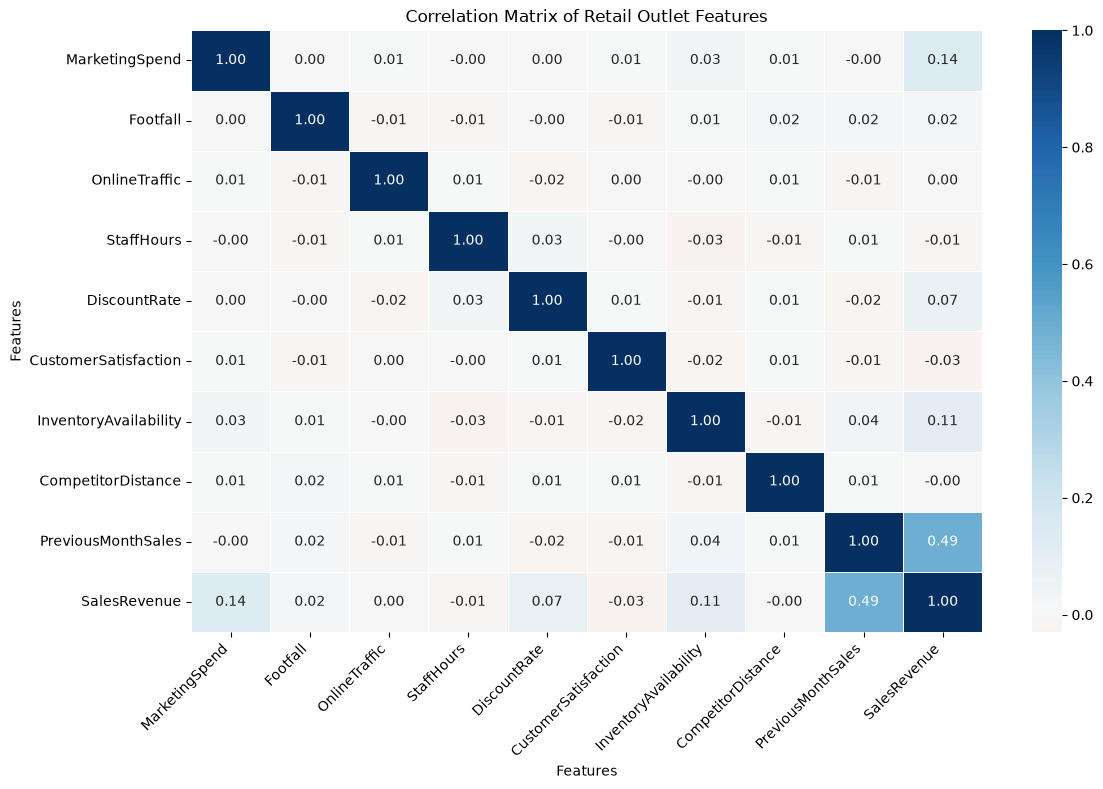

In [18]:
# Create a heatmap of the correlations
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="RdBu",
    center=0,
    linewidths=0.5,
)

plt.title("Correlation Matrix of Retail Outlet Features")
plt.xlabel("Features")
plt.ylabel("Features")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

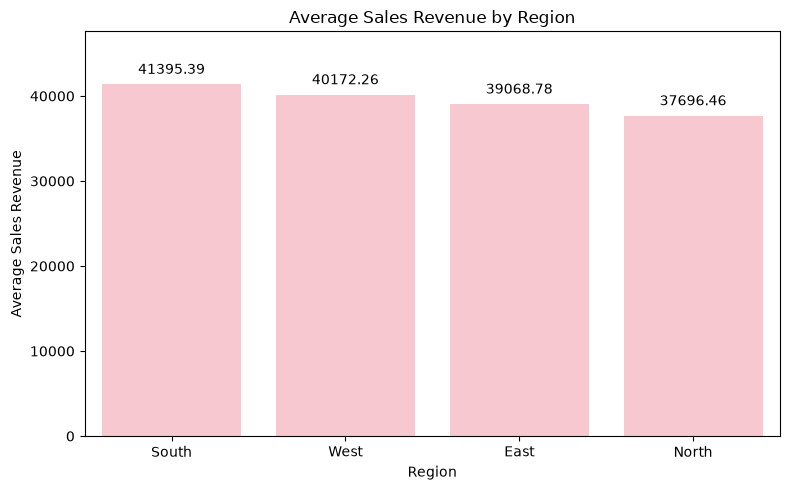

In [19]:
# Calculate average sales by region
region_sales = (
    retail_outlets.groupby("Region", as_index=False)["SalesRevenue"]
    .mean()
    .sort_values("SalesRevenue", ascending=False)
)

# Create the bar chart
plt.figure(figsize=(8, 5))
ax = sns.barplot(
    data=region_sales,
    x="Region",
    y="SalesRevenue",
    order=region_sales["Region"],
    color="pink",
)

# Add value labels above the bars
for bar in ax.patches:
    ax.annotate(
        f"{bar.get_height():.2f}",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom",
        xytext=(0, 5),
        textcoords="offset points",
    )

plt.title("Average Sales Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Average Sales Revenue")
plt.ylim(0, region_sales["SalesRevenue"].max() * 1.15)
plt.tight_layout()
plt.show()

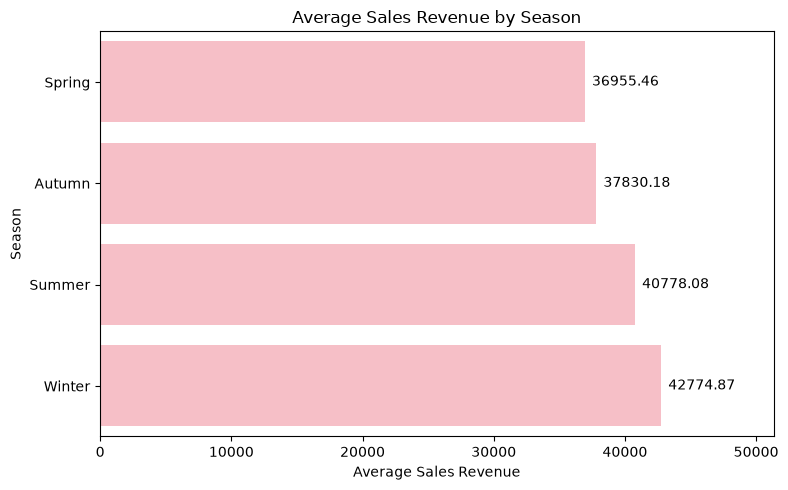

In [20]:
# Calculate average sales by season
season_sales = (
    retail_outlets.groupby("Season", as_index=False)["SalesRevenue"]
    .mean()
    .sort_values("SalesRevenue", ascending=False)
)

# Create the horizontal bar chart
plt.figure(figsize=(8, 5))
ax = sns.barplot(
    data=season_sales,
    x="SalesRevenue",
    y="Season",
    order=season_sales["Season"],
    color="lightpink",
)

# Add value labels
for bar in ax.patches:
    ax.annotate(
        f"{bar.get_width():.2f}",
        (bar.get_width(), bar.get_y() + bar.get_height() / 2),
        ha="left",
        va="center",
        xytext=(5, 0),
        textcoords="offset points",
    )

ax.invert_yaxis()
plt.title("Average Sales Revenue by Season")
plt.xlabel("Average Sales Revenue")
plt.ylabel("Season")
plt.xlim(0, season_sales["SalesRevenue"].max() * 1.20)
plt.tight_layout()
plt.show()

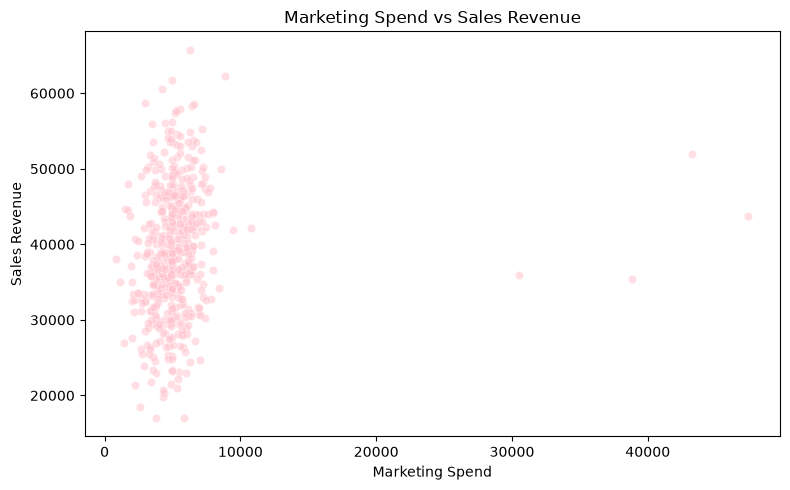

In [21]:
# Create the scatter plot
plt.figure(figsize=(8, 5))
sample_data = retail_outlets.sample(n=500, random_state=42)

sns.scatterplot(
    data=sample_data,
    x="MarketingSpend",
    y="SalesRevenue",
    color="pink",
    alpha=0.5,
)

plt.title("Marketing Spend vs Sales Revenue")
plt.xlabel("Marketing Spend")
plt.ylabel("Sales Revenue")
plt.tight_layout()
plt.show()

In [22]:
from sklearn.model_selection import train_test_split

# Separate features and target
X = retail_outlets.drop(columns=["SalesRevenue", "StoreID", "SalesChange"])
y = retail_outlets["SalesRevenue"]

# Convert categorical columns to numeric columns
X = pd.get_dummies(X, drop_first=True)

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training features shape: (4000, 21)
Testing features shape: (1000, 21)
Training target shape: (4000,)
Testing target shape: (1000,)


In [23]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Train the model
model = LinearRegression()
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

# Calculate metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred) ** 0.5
r2 = r2_score(y_test, y_pred)

# Display results
print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R²: {r2:.2f}")

MAE: 5006.95
RMSE: 6261.48
R²: 0.42


In [24]:
from sklearn.ensemble import RandomForestRegressor

# Train the model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
)
rf_model.fit(X_train, y_train)

# Make predictions
rf_y_pred = rf_model.predict(X_test)

# Calculate metrics
rf_mae = mean_absolute_error(y_test, rf_y_pred)
rf_rmse = mean_squared_error(y_test, rf_y_pred) ** 0.5
rf_r2 = r2_score(y_test, rf_y_pred)

# Display results
print(f"MAE: {rf_mae:.2f}")
print(f"RMSE: {rf_rmse:.2f}")
print(f"R²: {rf_r2:.2f}")

MAE: 5193.65
RMSE: 6463.18
R²: 0.39


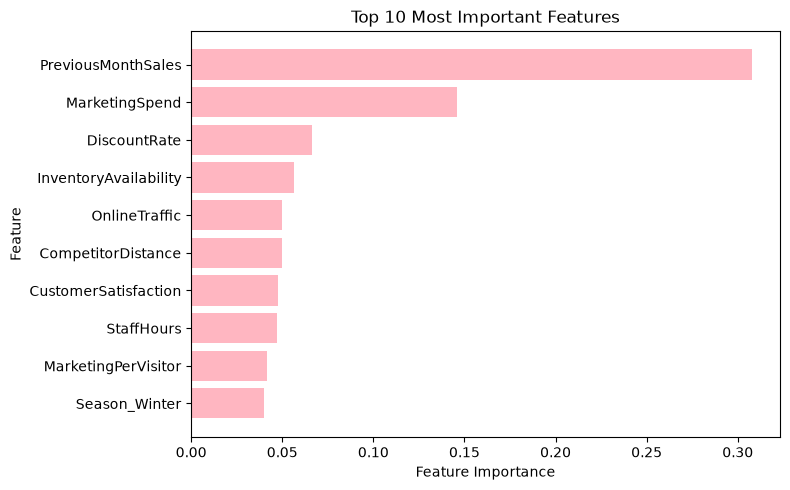

In [25]:
# Get the 10 most important features
feature_importance = pd.Series(
    rf_model.feature_importances_,
    index=X_train.columns,
).sort_values(ascending=False).head(10).sort_values()

# Create the horizontal bar chart
plt.figure(figsize=(8, 5))
plt.barh(feature_importance.index, feature_importance.values, color="lightpink")

plt.title("Top 10 Most Important Features")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()